# Estimación por intervalos: medias y proporciones con nivel de confianza

Desarrollo de los ejercicios de estimación por intervalos para una sola población: intervalos de
confianza de la media de una distribución normal con varianza conocida, intervalos de confianza de una
proporción poblacional y cálculo del tamaño de muestra necesario para acotar el error muestral. Los
intervalos se construyen con el cuantil de la normal estándar, se verifican numéricamente (colas del
cuantil, condiciones de aproximación, redondeo del tamaño de muestra) y se contrastan por simulación
Monte Carlo de la cobertura con semilla fija.

## Marco teórico

### Estimación por intervalos

La estimación puntual devuelve un solo número e informa mal sobre su dispersión. La estimación por
intervalos devuelve un rango $[\,L, U\,]$ calculado sobre la muestra, junto con un **nivel de
confianza** $1 - \alpha$ que mide la confiabilidad del procedimiento de construcción:

$$P(L \le \theta \le U) = 1 - \alpha$$

La probabilidad se refiere al procedimiento y no al intervalo ya obtenido: si se repitiera el muestreo
y se reconstruyera el intervalo muchas veces, el $100(1-\alpha)\%$ de esos intervalos contendría al
parámetro. Una vez observada la muestra, el intervalo es un rango fijo que o contiene a $\theta$ o no;
afirmar que "la probabilidad de que $\mu$ caiga en el intervalo es 0.95" es una interpretación
incorrecta del modelo frecuentista. $\alpha$ es la probabilidad de error, la de construir un intervalo
que excluya al parámetro.

### Método del estadístico pivote

Sea $T = T(X_1, \dots, X_n;\, \theta)$ un estadístico cuya distribución no depende del parámetro
(**pivote**). Si $a$ y $b$ verifican $P(a \le T \le b) = 1 - \alpha$, despejar $\theta$ de la
desigualdad entrega el intervalo. Para la media de una normal con $\sigma$ conocida el pivote es

$$Z = \frac{\bar X - \mu}{\sigma/\sqrt{n}} \sim N(0,1)$$

y tomando $-z_{\alpha/2} \le Z \le z_{\alpha/2}$, con $P(Z > z_{\alpha/2}) = \alpha/2$, se llega a

$$P\left(\bar X - z_{\alpha/2}\frac{\sigma}{\sqrt{n}} \le \mu \le \bar X + z_{\alpha/2}\frac{\sigma}{\sqrt{n}}\right) = 1 - \alpha$$

### Intervalo de confianza de la media con varianza conocida

$$\bar x \ \pm \ z_{\alpha/2}\,\frac{\sigma}{\sqrt{n}}$$

El término $E = z_{\alpha/2}\,\sigma/\sqrt{n}$ es el **error muestral** o semiamplitud; la amplitud del
intervalo es $2E$. De la expresión se desprenden tres relaciones operativas que gobiernan todos los
ejercicios:

1. A mayor nivel de confianza, mayor $z_{\alpha/2}$ y mayor amplitud: la confianza se paga con
   precisión.
2. El error decrece como $1/\sqrt{n}$: reducir a la mitad la amplitud exige cuatro veces más
   observaciones.
3. El error es proporcional a $\sigma$: tanta más variabilidad poblacional, muestras más grandes.

### Cuantiles de referencia

| Nivel $1-\alpha$ | $\alpha$ | $\alpha/2$ | $z_{\alpha/2}$ |
|---|---|---|---|
| 0.90 | 0.10 | 0.05 | 1.644854 |
| 0.95 | 0.05 | 0.025 | 1.959964 |
| 0.98 | 0.02 | 0.01 | 2.326348 |
| 0.99 | 0.01 | 0.005 | 2.575829 |

### Población no normal: teorema del límite central

Si la forma de la población se desconoce, el intervalo anterior requiere que $\bar X$ sea
aproximadamente normal. Por el teorema del límite central eso ocurre cuando el tamaño de muestra es
grande; la regla operativa es $n \ge 30$. Con muestras pequeñas y población no normal, el intervalo
con $z$ no alcanza el nivel de confianza declarado y corresponde usar la $t$ de Student (varianza
desconocida) o un método no paramétrico. Una varianza conocida o estimada con precisión por datos
previos habilita el uso de $z$ aunque la población no sea normal, siempre que la muestra sea grande.

### Transformación lineal del intervalo

Si $[L, U]$ es un intervalo de confianza para $\theta$ y $c > 0$, entonces $[cL,\, cU]$ lo es para
$c\theta$: la transformación es monótona creciente y preserva la cobertura. Permite traducir un
intervalo de media a unidades de costo, tasa o precio multiplicando los límites, sin reconstruir el
intervalo desde cero.

### Intervalo de confianza de una proporción

Sea $X$ el número de éxitos en $n$ ensayos independientes con probabilidad de éxito $p$. El estimador
es $\hat p = X/n$, con $E[\hat p] = p$ y $\operatorname{Var}(\hat p) = p(1-p)/n$; por el teorema del
límite central,

$$\frac{\hat p - p}{\sqrt{p(1-p)/n}} \ \dot\sim \ N(0,1)$$

Como $p$ es desconocido, se sustituye por su estimación en el error estándar (estimador sustituto) y
se obtiene el intervalo de Wald:

$$\hat p \ \pm \ z_{\alpha/2}\,\sqrt{\frac{\hat p\,(1-\hat p)}{n}}$$

Condición de validez: $n\hat p \ge 5$ y $n(1-\hat p) \ge 5$, de modo que la aproximación normal sea
razonable. La cobertura del intervalo de Wald es aproximada y puede quedar por encima o por debajo del
nivel declarado según el valor de $p$; con muestras pequeñas se prefiere el intervalo de Wilson o el
de score, y para $p$ cerca de 0 o de 1 la normalización de una transformación (logit, arcseno) mejora
el comportamiento.

### Población finita

Cuando la muestra se extrae sin reposición de una población finita de tamaño $N$ y $n/N > 0.05$, la
varianza del estimador se ajusta por el factor de corrección por finitud, porque los elementos ya
muestreados dejan de estar disponibles:

$$\sqrt{\frac{N - n}{N - 1}} < 1$$

El intervalo se estrecha: muestrear una fracción apreciable de la población aporta más información de
la que supone el modelo con reposición.

### Tamaño de la muestra

Fijados el nivel de confianza y el error muestral máximo $E$, el tamaño se despeja de la fórmula del
intervalo. Para la media con $\sigma$ conocida:

$$n = \left(\frac{z_{\alpha/2}\,\sigma}{E}\right)^2$$

y para una proporción:

$$n = \frac{z_{\alpha/2}^{\,2}\, p(1-p)}{E^2}$$

Como $n$ es entero y el error decrece con el tamaño de muestra, se redondea siempre hacia arriba: el
valor obtenido por el cociente no es admisible porque excedería la tolerancia fijada. Para la
proporción la varianza poblacional depende del parámetro que se ignora; si $p$ se desconoce se toma
$p = 0.5$, que maximiza $p(1-p)$ y por lo tanto el tamaño requerido. Es la elección conservadora: un
valor real distinto solo puede reducir el tamaño necesario, nunca aumentarlo.

In [1]:

import math

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

AZUL = "#1f4e79"
GRIS = "#808080"
VERDE = "#2e7d32"
ROJO = "#b03a2e"

# cuantiles de la normal estandar: P(Z > z) = alpha/2 para cada nivel de confianza
Z = {0.90: 1.644854, 0.95: 1.959964, 0.98: 2.326348, 0.99: 2.575829}


def cola_normal(z):
    """P(Z > z) para Z ~ N(0,1), via la funcion error complementaria."""
    return 0.5 * math.erfc(z / math.sqrt(2))


print("numpy", np.__version__, "| matplotlib", mpl.__version__)
print()
print(f"{'nivel':>7}{'z':>12}{'cola P(Z > z)':>17}{'alpha/2':>12}")
print("-" * 48)
for nivel, z in Z.items():
    print(f"{nivel:>7.2f}{z:>12.6f}{cola_normal(z):>17.6f}{(1 - nivel) / 2:>12.6f}")


numpy 2.4.4 | matplotlib 3.10.9

  nivel           z    cola P(Z > z)     alpha/2
------------------------------------------------
   0.90    1.644854         0.050000    0.050000
   0.95    1.959964         0.025000    0.025000
   0.98    2.326348         0.010000    0.010000
   0.99    2.575829         0.005000    0.005000


## 1. Consumo eléctrico: intervalo para la media con varianza conocida

Se quiere estimar el consumo promedio de energía eléctrica de los residentes de una ciudad durante
diciembre. Se seleccionan al azar $n = 61$ residentes y el consumo promedio observado es
$\bar x = 984$ kWh. La varianza del consumo se estima en $\sigma^2 = 431$ kWh$^2$ (de donde
$\sigma = \sqrt{431} = 20.7605$ kWh) y se la trata como conocida; la forma de la distribución
poblacional se desconoce.

Con $\sigma$ conocida y $n = 61 \ge 30$, el teorema del límite central justifica el pivote normal
aunque la población no sea normal. El error estándar de la media muestral es

$$\frac{\sigma}{\sqrt{n}} = \frac{\sqrt{431}}{\sqrt{61}} = \frac{20.7605}{7.8102} = 2.6581 \text{ kWh}$$

### a) Intervalo con confianza del 90%

Con $1 - \alpha = 0.90$ resulta $\alpha/2 = 0.05$ y $z_{0.05} = 1.644854$:

$$\bar x \pm z_{0.05}\frac{\sigma}{\sqrt{n}} = 984 \pm 1.644854 \times 2.6581 = 984 \pm 4.372$$

$$979.63 \ \le \ \mu \ \le \ 988.37 \text{ kWh}$$

Con una confianza del 90%, el consumo promedio de diciembre se sitúa entre 979.63 y 988.37 kWh. La
amplitud del intervalo es de 8.74 kWh, apenas el 0.9% del consumo medio: el tamaño de muestra compensa
la variabilidad del error estándar (2.6581 kWh) multiplicándola solo 1.64 veces.

### b) Intervalo con confianza del 99%

Con $1 - \alpha = 0.99$ resulta $\alpha/2 = 0.005$ y $z_{0.005} = 2.575829$:

$$984 \pm 2.575829 \times 2.6581 = 984 \pm 6.847$$

$$977.15 \ \le \ \mu \ \le \ 990.85 \text{ kWh}$$

El intervalo del 99% es más amplio que el del 90%, como exige la relación entre confianza y
precisión: para el mismo tamaño de muestra, cubrir al parámetro con mayor probabilidad obliga a
ensanchar el rango. El error muestral crece en la razón $2.575829/1.644854 = 1.566$, es decir un 56.6%
más de amplitud a cambio de 9 puntos de confianza adicionales.

### c) Intervalo para el costo promedio

El precio de la energía es de \$109.45 por kWh (cuadro tarifario T1-G2, septiembre de 2024). El costo
promedio por residente es el producto del consumo por el precio, una transformación lineal creciente,
de modo que basta multiplicar los límites del intervalo del inciso a):

$$109.45 \times [\,979.6278, \ 988.3722\,] = [\,107\,220.26, \ 108\,177.34\,]$$

Con una confianza del 90%, el costo promedio de diciembre por residente queda entre \$107,220.26 y
\$108,177.34. El nivel de confianza no cambia al escalar el intervalo: si el consumo queda cubierto,
queda cubierto el costo correspondiente, y la amplitud en pesos es \$957.08, el 0.89% del valor central.

In [2]:
n = 61
xbar = 984.0
sigma2 = 431.0
sigma = math.sqrt(sigma2)
precio = 109.45                     # $ por kWh

se = sigma / math.sqrt(n)

print(f"n = {n}, xbar = {xbar} kWh, sigma^2 = {sigma2} kWh^2 -> sigma = {sigma:.4f} kWh")
print(f"error estandar: sigma/sqrt(n) = {sigma:.4f}/{math.sqrt(n):.4f} = {se:.4f} kWh")
print()

margenes = {}
for nivel in (0.90, 0.99):
    z = Z[nivel]
    margen = z * se
    margenes[nivel] = margen
    print(f"nivel {nivel:.0%}: z = {z:.6f} -> margen = {z:.6f} x {se:.4f} = {margen:.4f} kWh")
    print(f"   intervalo: [{xbar - margen:.2f}, {xbar + margen:.2f}] kWh"
          f"   amplitud {2 * margen:.2f} kWh ({2 * margen / xbar:.2%} del promedio)")

# c) costo promedio: transformacion lineal del intervalo del 90%
costo_inf = precio * (xbar - margenes[0.90])
costo_sup = precio * (xbar + margenes[0.90])

print()
print(f"c) precio = {precio} $/kWh")
print(f"   costo promedio entre {costo_inf:.2f} y {costo_sup:.2f} $"
      f"   amplitud {costo_sup - costo_inf:.2f} $")


n = 61, xbar = 984.0 kWh, sigma^2 = 431.0 kWh^2 -> sigma = 20.7605 kWh
error estandar: sigma/sqrt(n) = 20.7605/7.8102 = 2.6581 kWh

nivel 90%: z = 1.644854 -> margen = 1.644854 x 2.6581 = 4.3722 kWh
   intervalo: [979.63, 988.37] kWh   amplitud 8.74 kWh (0.89% del promedio)
nivel 99%: z = 2.575829 -> margen = 2.575829 x 2.6581 = 6.8468 kWh
   intervalo: [977.15, 990.85] kWh   amplitud 13.69 kWh (1.39% del promedio)

c) precio = 109.45 $/kWh
   costo promedio entre 107220.26 y 108177.34 $   amplitud 957.08 $


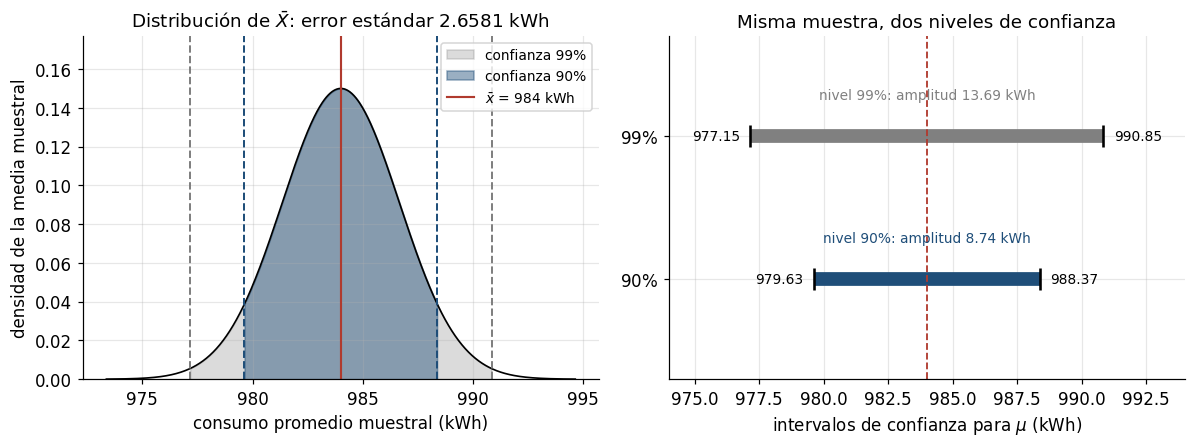

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

malla = np.linspace(xbar - 4 * se, xbar + 4 * se, 700)
densidad = np.exp(-0.5 * ((malla - xbar) / se) ** 2) / (se * math.sqrt(2 * math.pi))

axs[0].plot(malla, densidad, color="black", linewidth=1.1)
for nivel, color, alfa in [(0.99, GRIS, 0.28), (0.90, AZUL, 0.45)]:
    z = Z[nivel]
    dentro = np.abs(malla - xbar) <= z * se
    axs[0].fill_between(malla, 0, densidad, where=dentro, color=color, alpha=alfa,
                        label=f"confianza {nivel:.0%}")
    axs[0].axvline(xbar - z * se, color=color, linewidth=1.3, linestyle="--")
    axs[0].axvline(xbar + z * se, color=color, linewidth=1.3, linestyle="--")
axs[0].axvline(xbar, color=ROJO, linewidth=1.4, label=r"$\bar{x}$ = 984 kWh")
axs[0].set_xlabel("consumo promedio muestral (kWh)")
axs[0].set_ylabel("densidad de la media muestral")
axs[0].set_ylim(0, densidad.max() * 1.18)
axs[0].set_title(r"Distribución de $\bar{X}$: error estándar 2.6581 kWh")
axs[0].legend(fontsize=9)

for y, nivel, color in [(1, 0.99, GRIS), (0, 0.90, AZUL)]:
    z = Z[nivel]
    lo, hi = xbar - z * se, xbar + z * se
    axs[1].hlines(y, lo, hi, color=color, linewidth=9)
    axs[1].plot([lo, hi], [y, y], "|", color="black", markersize=14, markeredgewidth=1.7)
    axs[1].text(lo - 0.4, y, f"{lo:.2f}", ha="right", va="center", fontsize=9)
    axs[1].text(hi + 0.4, y, f"{hi:.2f}", ha="left", va="center", fontsize=9)
    axs[1].text((lo + hi) / 2, y + 0.26, f"nivel {nivel:.0%}: amplitud {hi - lo:.2f} kWh",
                ha="center", fontsize=9, color=color)
axs[1].axvline(xbar, color=ROJO, linewidth=1.2, linestyle="--")
axs[1].set_yticks([0, 1], [r"$90\%$", r"$99\%$"])
axs[1].set_ylim(-0.7, 1.7)
axs[1].set_xlim(974, 994)
axs[1].set_xlabel(r"intervalos de confianza para $\mu$ (kWh)")
axs[1].set_title("Misma muestra, dos niveles de confianza")

plt.tight_layout()
plt.show()


La simulación siguiente repite el procedimiento completo, muestra tras muestra, y cuenta qué fracción
de los intervalos construidos contiene al consumo promedio verdadero. Es la comprobación directa de la
interpretación frecuentista del nivel de confianza: con población normal y $\sigma$ conocida, la
cobertura es exactamente $1 - \alpha$, y lo que fluctúa es el intervalo, no el parámetro.

In [4]:
# verificacion de la cobertura: fraccion de intervalos que contiene al parametro verdadero
rng = np.random.default_rng(7)
ensayos = 20_000

mu_real = xbar
simuladas = rng.normal(mu_real, sigma, size=(ensayos, n))
medias = simuladas.mean(axis=1)

print(f"poblacion de referencia: mu = {mu_real} kWh, sigma = {sigma:.4f} kWh")
print(f"ensayos Monte Carlo: {ensayos:,}")
print()
print(f"{'nivel':>7}{'margen':>10}{'cobertura simulada':>22}{'cobertura nominal':>20}")
print("-" * 60)
for nivel in (0.90, 0.95, 0.99):
    margen = Z[nivel] * se
    cobertura = (np.abs(medias - mu_real) <= margen).mean()
    print(f"{nivel:>7.0%}{margen:>10.4f}{cobertura:>22.4f}{nivel:>20.2f}")

margen_90 = margenes[0.90]
print()
print(f"con un error estandar de {se:.4f} kWh, la fluctuacion entre muestras explica que")
print(f"solo {(np.abs(medias - mu_real) > margen_90).mean() * ensayos:.0f} de {ensayos:,} muestras")
print(f"caigan fuera del intervalo del 90%")


poblacion de referencia: mu = 984.0 kWh, sigma = 20.7605 kWh
ensayos Monte Carlo: 20,000

  nivel    margen    cobertura simulada   cobertura nominal
------------------------------------------------------------
    90%    4.3722                0.8989                0.90
    95%    5.2098                0.9489                0.95
    99%    6.8468                0.9895                0.99

con un error estandar de 2.6581 kWh, la fluctuacion entre muestras explica que
solo 2023 de 20,000 muestras
caigan fuera del intervalo del 90%


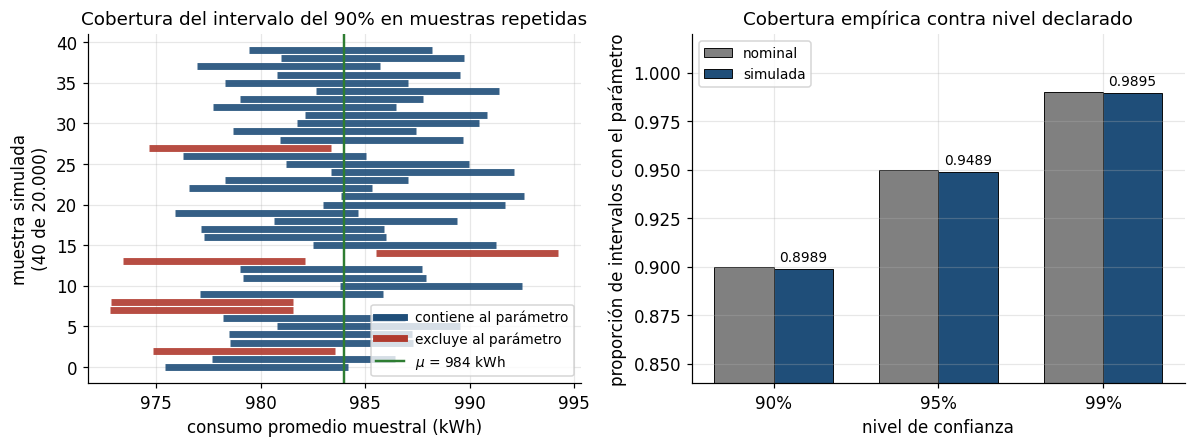

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

for i, media in enumerate(medias[:40]):
    dentro = abs(media - mu_real) <= margen_90
    axs[0].hlines(i, media - margen_90, media + margen_90,
                  color=AZUL if dentro else ROJO, linewidth=4.5, alpha=0.9)
axs[0].plot([], [], color=AZUL, linewidth=4.5, label="contiene al parámetro")
axs[0].plot([], [], color=ROJO, linewidth=4.5, label="excluye al parámetro")
axs[0].axvline(mu_real, color=VERDE, linewidth=1.6, label=r"$\mu$ = 984 kWh")
axs[0].set_xlabel("consumo promedio muestral (kWh)")
axs[0].set_ylabel("muestra simulada\n(40 de 20.000)")
axs[0].set_ylim(-2, 41)
axs[0].set_title("Cobertura del intervalo del 90% en muestras repetidas")
axs[0].legend(fontsize=9, loc="lower right")

niveles = [0.90, 0.95, 0.99]
cobertura_sim = [(np.abs(medias - mu_real) <= Z[v] * se).mean() for v in niveles]
pos = np.arange(len(niveles))

axs[1].bar(pos - 0.18, niveles, width=0.36, color=GRIS, edgecolor="black", linewidth=0.6,
           label="nominal")
axs[1].bar(pos + 0.18, cobertura_sim, width=0.36, color=AZUL, edgecolor="black", linewidth=0.6,
           label="simulada")
for x_pos, valor in zip(pos + 0.18, cobertura_sim):
    axs[1].text(x_pos, valor + 0.004, f"{valor:.4f}", ha="center", fontsize=9)
axs[1].set_xticks(pos, [f"{v:.0%}" for v in niveles])
axs[1].set_xlabel("nivel de confianza")
axs[1].set_ylabel("proporción de intervalos con el parámetro")
axs[1].set_ylim(0.84, 1.02)
axs[1].set_title("Cobertura empírica contra nivel declarado")
axs[1].legend(fontsize=9)

plt.tight_layout()
plt.show()


## 2. Fallas de aleaciones: intervalo para una proporción

De un registro de $n = 295$ fallas de aleaciones de acero inoxidable ocurridas en refinerías de
petróleo, $x = 118$ se debieron a corrosión bajo tensión, el mecanismo asociado a esfuerzos mecánicos
en ambientes corrosivos. Se busca un intervalo de confianza del 98% para la proporción poblacional $p$
de fallas causadas por ese mecanismo.

La estimación puntual es la proporción muestral:

$$\hat p = \frac{x}{n} = \frac{118}{295} = 0.40$$

Cada falla del registro se trata como un ensayo con la misma probabilidad de causa y los ensayos
resultan independientes por el muestreo aleatorio, de modo que el número de fallas por corrosión bajo
tensión es una variable binomial. Condición de aproximación normal: $n\hat p = 118 \ge 5$ y
$n(1-\hat p) = 177 \ge 5$, cumplida holgadamente.

Con $1 - \alpha = 0.98$ resulta $z_{0.01} = 2.326348$. El error estándar de la proporción muestral y
el intervalo de Wald son

$$\sqrt{\frac{\hat p(1-\hat p)}{n}} = \sqrt{\frac{0.40 \times 0.60}{295}} = \sqrt{0.0008136} = 0.028523$$

$$0.40 \pm 2.326348 \times 0.028523 = 0.40 \pm 0.0664$$

$$0.3336 \ \le \ p \ \le \ 0.4664$$

Entre el 33.4% y el 46.6% de las fallas de aleaciones se explicarían por corrosión bajo tensión, con
una confianza del 98%. La amplitud es de 13.3 puntos porcentuales, bastante amplia pese a las casi 300
observaciones: la varianza de $\hat p$ es máxima en $\hat p = 0.5$ y el valor observado está en ese
peor caso, de modo que ninguna proporción podría estimarse con menor error muestral usando el mismo
tamaño de muestra.

In [6]:
n_fallas = 295
x_fallas = 118
p_hat = x_fallas / n_fallas
z = Z[0.98]

se_p = math.sqrt(p_hat * (1 - p_hat) / n_fallas)
margen = z * se_p
lim_inf, lim_sup = p_hat - margen, p_hat + margen

print(f"n = {n_fallas} fallas, x = {x_fallas} por corrosion bajo tension")
print(f"p_hat = {x_fallas}/{n_fallas} = {p_hat:.4f}")
print(f"condicion normal: n*p_hat = {n_fallas * p_hat:.0f} >= 5, "
      f"n*(1-p_hat) = {n_fallas * (1 - p_hat):.0f} >= 5")
print()
print(f"error estandar: sqrt({p_hat:.2f} x {1 - p_hat:.2f} / {n_fallas}) = {se_p:.6f}")
print(f"nivel 98%: z = {z:.6f} -> margen = {z:.6f} x {se_p:.6f} = {margen:.6f}")
print(f"intervalo: [{lim_inf:.4f}, {lim_sup:.4f}]")
print(f"lectura: entre el {lim_inf:.1%} y el {lim_sup:.1%} de las fallas, amplitud "
      f"{lim_sup - lim_inf:.4f} ({100 * (lim_sup - lim_inf):.2f} puntos porcentuales)")


n = 295 fallas, x = 118 por corrosion bajo tension
p_hat = 118/295 = 0.4000
condicion normal: n*p_hat = 118 >= 5, n*(1-p_hat) = 177 >= 5

error estandar: sqrt(0.40 x 0.60 / 295) = 0.028523
nivel 98%: z = 2.326348 -> margen = 2.326348 x 0.028523 = 0.066354
intervalo: [0.3336, 0.4664]
lectura: entre el 33.4% y el 46.6% de las fallas, amplitud 0.1327 (13.27 puntos porcentuales)


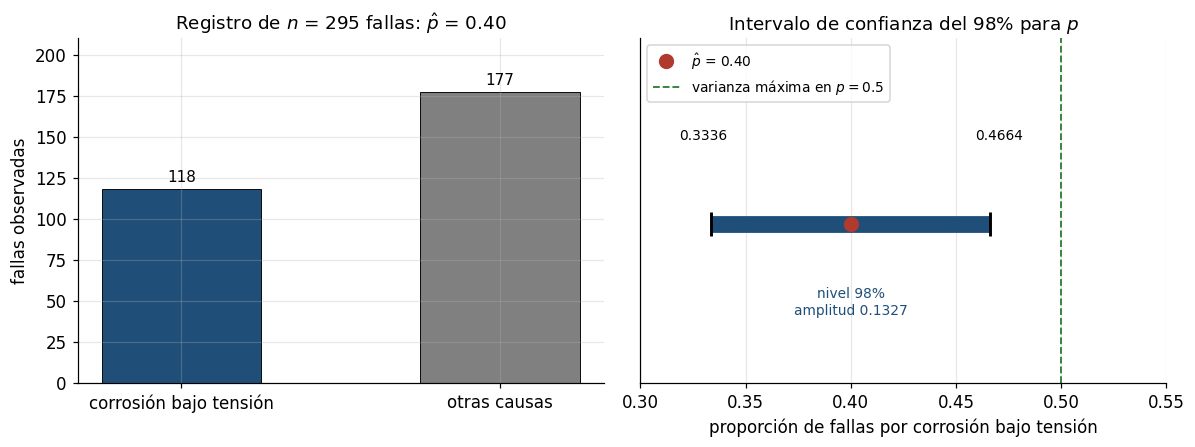

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

barras = axs[0].bar(["corrosión bajo tensión", "otras causas"], [x_fallas, n_fallas - x_fallas],
                    width=0.5, color=[AZUL, GRIS], edgecolor="black", linewidth=0.6)
for rect, valor in zip(barras, [x_fallas, n_fallas - x_fallas]):
    axs[0].text(rect.get_x() + rect.get_width() / 2, valor + 5, f"{valor}", ha="center", fontsize=10)
axs[0].set_ylabel("fallas observadas")
axs[0].set_ylim(0, 210)
axs[0].set_title(r"Registro de $n$ = 295 fallas: $\hat{p}$ = 0.40")

axs[1].hlines(0, lim_inf, lim_sup, color=AZUL, linewidth=11)
axs[1].plot([lim_inf, lim_sup], [0, 0], "|", color="black", markersize=16, markeredgewidth=1.9)
axs[1].plot(p_hat, 0, "o", color=ROJO, markersize=9, zorder=5, label=r"$\hat{p}$ = 0.40")
axs[1].axvline(0.5, color=VERDE, linestyle="--", linewidth=1.2,
               label=r"varianza máxima en $p = 0.5$")
axs[1].text(lim_inf - 0.004, 0.16, f"{lim_inf:.4f}", ha="center", fontsize=9)
axs[1].text(lim_sup + 0.004, 0.16, f"{lim_sup:.4f}", ha="center", fontsize=9)
axs[1].text((lim_inf + lim_sup) / 2, -0.17, f"nivel 98%\namplitud {lim_sup - lim_inf:.4f}",
            ha="center", fontsize=9, color=AZUL)
axs[1].set_xlim(0.30, 0.55)
axs[1].set_ylim(-0.3, 0.35)
axs[1].set_yticks([])
axs[1].set_xlabel("proporción de fallas por corrosión bajo tensión")
axs[1].set_title("Intervalo de confianza del 98% para $p$")
axs[1].legend(fontsize=9, loc="upper left")

plt.tight_layout()
plt.show()


## 3. Restaurantes: intervalo para una proporción y su traducción a cantidad

Una ciudad cuenta con unos $N = 500$ restaurantes y se quiere estimar la proporción que aceptaría
participar en un servicio de reservas por internet. En una muestra al azar de $n = 50$ restaurantes,
$x = 20$ respondieron afirmativamente:

$$\hat p = \frac{20}{50} = 0.40, \qquad n\hat p = 20 \ge 5, \qquad n(1-\hat p) = 30 \ge 5$$

Las condiciones de aproximación normal se cumplen.

### a) Límites de confianza del 95%

Con $z_{0.025} = 1.959964$ y error estándar $\sqrt{0.40 \times 0.60 / 50} = \sqrt{0.0048} = 0.069282$:

$$0.40 \pm 1.959964 \times 0.069282 = 0.40 \pm 0.1358$$

$$0.2642 \ \le \ p \ \le \ 0.5358$$

Con una confianza del 95%, la proporción de restaurantes que aceptaría la propuesta está entre el
26.4% y el 53.6%. El intervalo cruza el 50%, de modo que la muestra no permite afirmar ni que la
mayoría aceptaría ni que la mayoría rechazaría.

### b) Cantidad de restaurantes

Como la población es finita y su tamaño es conocido, el intervalo de proporciones se traduce en
cantidad multiplicando por $N = 500$:

$$500 \times [\,0.2642, \ 0.5358\,] = [\,132.1, \ 267.9\,]$$

Entre unos 132 y 268 restaurantes de los 500 aceptarían participar, con una confianza del 95%. Es la
misma afirmación del inciso a) en otra unidad: la multiplicación por una constante positiva preserva
la cobertura del intervalo.

### Nota: corrección por finitud de la población

La muestra cubre el 10% de la población ($n/N = 50/500$), un umbral a partir del cual conviene
corregir el error estándar por la finitud de la población. El factor es

$$\sqrt{\frac{N - n}{N - 1}} = \sqrt{\frac{450}{499}} = 0.9496$$

y reduce el error muestral de 0.1358 a 0.1290, estrechando el intervalo:

$$0.40 \pm 0.1290 = [\,0.2710, \ 0.5290\,] \qquad \Longrightarrow \qquad [\,135.5, \ 264.5\,] \text{ restaurantes}$$

La corrección es legítima porque el muestreo es sin reposición de una población finita: los
restaurantes ya encuestados dejan de estar disponibles y la muestra aporta más información de la que
supone el modelo con reposición. El ejercicio se resuelve con el intervalo estándar; el cálculo
corregido queda como contraste del orden de magnitud del efecto.

In [8]:
N_pob, n = 500, 50
x = 20
p_hat = x / n
z = Z[0.95]

se_p = math.sqrt(p_hat * (1 - p_hat) / n)
margen = z * se_p
fpc = math.sqrt((N_pob - n) / (N_pob - 1))
margen_fpc = margen * fpc

print(f"poblacion N = {N_pob}, muestra n = {n} (n/N = {n / N_pob:.0%}), exitos = {x}")
print(f"p_hat = {p_hat:.4f}; n*p_hat = {n * p_hat:.0f} >= 5, "
      f"n*(1-p_hat) = {n * (1 - p_hat):.0f} >= 5")
print()
print(f"a) error estandar = {se_p:.6f}, z = {z:.6f} -> margen = {margen:.6f}")
print(f"   intervalo para p: [{p_hat - margen:.4f}, {p_hat + margen:.4f}]")
print()
print(f"b) multiplicando por N = {N_pob}:")
print(f"   [{(p_hat - margen) * N_pob:.1f}, {(p_hat + margen) * N_pob:.1f}] restaurantes")
print()
print(f"nota: factor de finitud sqrt((N-n)/(N-1)) = {fpc:.4f}")
print(f"   margen corregido = {margen_fpc:.6f} -> p en "
      f"[{p_hat - margen_fpc:.4f}, {p_hat + margen_fpc:.4f}]")
print(f"   en cantidad: [{(p_hat - margen_fpc) * N_pob:.1f}, "
      f"{(p_hat + margen_fpc) * N_pob:.1f}] restaurantes")


poblacion N = 500, muestra n = 50 (n/N = 10%), exitos = 20
p_hat = 0.4000; n*p_hat = 20 >= 5, n*(1-p_hat) = 30 >= 5

a) error estandar = 0.069282, z = 1.959964 -> margen = 0.135790
   intervalo para p: [0.2642, 0.5358]

b) multiplicando por N = 500:
   [132.1, 267.9] restaurantes

nota: factor de finitud sqrt((N-n)/(N-1)) = 0.9496
   margen corregido = 0.128951 -> p en [0.2710, 0.5290]
   en cantidad: [135.5, 264.5] restaurantes


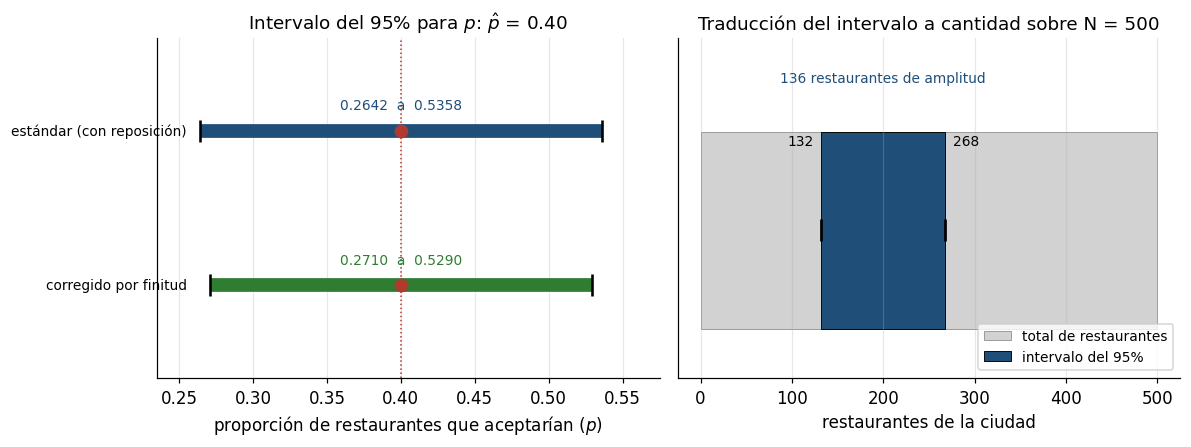

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

for y, etiqueta, margen_, color in [(1, "estándar (con reposición)", margen, AZUL),
                                    (0, "corregido por finitud", margen_fpc, VERDE)]:
    lo, hi = p_hat - margen_, p_hat + margen_
    axs[0].hlines(y, lo, hi, color=color, linewidth=9)
    axs[0].plot([lo, hi], [y, y], "|", color="black", markersize=14, markeredgewidth=1.7)
    axs[0].text((lo + hi) / 2, y + 0.14, f"{lo:.4f}  a  {hi:.4f}", ha="center", fontsize=9,
                color=color)
    axs[0].text(0.255, y, etiqueta, ha="right", va="center", fontsize=9)
axs[0].plot([p_hat, p_hat], [0, 1], "o", color=ROJO, markersize=8, zorder=5)
axs[0].axvline(p_hat, color=ROJO, linewidth=1.0, linestyle=":")
axs[0].set_xlim(0.235, 0.575)
axs[0].set_ylim(-0.6, 1.6)
axs[0].set_yticks([])
axs[0].set_xlabel(r"proporción de restaurantes que aceptarían ($p$)")
axs[0].set_title(r"Intervalo del 95% para $p$: $\hat{p}$ = 0.40")

barras = axs[1].barh([0], [N_pob], color=GRIS, alpha=0.35, edgecolor="black", linewidth=0.6,
                     label="total de restaurantes")
axs[1].barh([0], [(p_hat + margen) * N_pob - (p_hat - margen) * N_pob],
            left=[(p_hat - margen) * N_pob], color=AZUL, edgecolor="black", linewidth=0.6,
            label="intervalo del 95%")
axs[1].plot([(p_hat - margen) * N_pob, (p_hat + margen) * N_pob], [0, 0], "|", color="black",
            markersize=15, markeredgewidth=1.8)
axs[1].text((p_hat - margen) * N_pob - 8, 0.36, f"{(p_hat - margen) * N_pob:.0f}", ha="right",
            va="center", fontsize=9)
axs[1].text((p_hat + margen) * N_pob + 8, 0.36, f"{(p_hat + margen) * N_pob:.0f}", ha="left",
            va="center", fontsize=9)
axs[1].text(p_hat * N_pob, 0.60,
            f"{(p_hat + margen) * N_pob - (p_hat - margen) * N_pob:.0f} restaurantes de amplitud",
            ha="center", fontsize=9, color=AZUL)
axs[1].set_xlim(-25, 525)
axs[1].set_ylim(-0.6, 0.78)
axs[1].set_yticks([])
axs[1].set_xlabel("restaurantes de la ciudad")
axs[1].set_title("Traducción del intervalo a cantidad sobre N = 500")
axs[1].legend(fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 0.005))

plt.tight_layout()
plt.show()


## 4. Velocidad media en una ruta: tamaño de la muestra

Se quiere estimar la velocidad media de los vehículos que circulan por una ruta provincial con un
error muestral de $E = 5$ km/h. La desviación estándar de las velocidades se supone conocida,
$\sigma = 20$ km/h, a partir de datos previos del tránsito. El tamaño se despeja de la fórmula del
error muestral:

$$n = \left(\frac{z_{\alpha/2}\,\sigma}{E}\right)^2$$

### a) Confianza del 95%

Con $z_{0.025} = 1.959964$:

$$n = \left(\frac{1.959964 \times 20}{5}\right)^2 = (7.84)^2 = 61.47$$

Como el tamaño debe ser entero y el error decrece con $n$, se redondea hacia arriba: $n = 62$
vehículos. El redondeo no es un detalle de presentación: con $n = 61$ el error muestral sería 5.019
km/h, por encima de la tolerancia fijada.

### b) Confianza del 99%

Con $z_{0.005} = 2.575829$:

$$n = \left(\frac{2.575829 \times 20}{5}\right)^2 = (10.3033)^2 = 106.16 \ \Longrightarrow \ n = 107$$

Ganar 4 puntos de confianza cuesta 45 observaciones más, un incremento del 72.6%. La razón es el
cuadrado de la fórmula: el tamaño crece como $z^2$, y $(2.575829/1.959964)^2 = 1.73$.

In [10]:
sigma_v, E = 20.0, 5.0

print(f"sigma = {sigma_v} km/h, error muestral maximo E = {E} km/h")
print()

tamanios = {}
for nivel in (0.95, 0.99):
    z = Z[nivel]
    n_crudo = (z * sigma_v / E) ** 2
    n_ = math.ceil(n_crudo)
    tamanios[nivel] = n_
    e_con_menos = z * sigma_v / math.sqrt(n_ - 1)
    e_con = z * sigma_v / math.sqrt(n_)
    print(f"nivel {nivel:.0%}: z = {z:.6f} -> n = ({z * sigma_v:.4f}/{E})^2 = {n_crudo:.4f} "
          f"-> n = {n_}")
    print(f"   con n = {n_ - 1}: E = {e_con_menos:.4f} > {E}   |   "
          f"con n = {n_}: E = {e_con:.4f} <= {E}")

crecimiento = tamanios[0.99] / tamanios[0.95]
print()
print(f"razon de tamanios: {tamanios[0.99]}/{tamanios[0.95]} = {crecimiento:.4f}")
print(f"verificacion del cuadrado: (z99/z95)^2 = {(Z[0.99] / Z[0.95])**2:.4f}")


sigma = 20.0 km/h, error muestral maximo E = 5.0 km/h

nivel 95%: z = 1.959964 -> n = (39.1993/5.0)^2 = 61.4633 -> n = 62
   con n = 61: E = 5.0190 > 5.0   |   con n = 62: E = 4.9783 <= 5.0
nivel 99%: z = 2.575829 -> n = (51.5166/5.0)^2 = 106.1583 -> n = 107
   con n = 106: E = 5.0037 > 5.0   |   con n = 107: E = 4.9803 <= 5.0

razon de tamanios: 107/62 = 1.7258
verificacion del cuadrado: (z99/z95)^2 = 1.7272


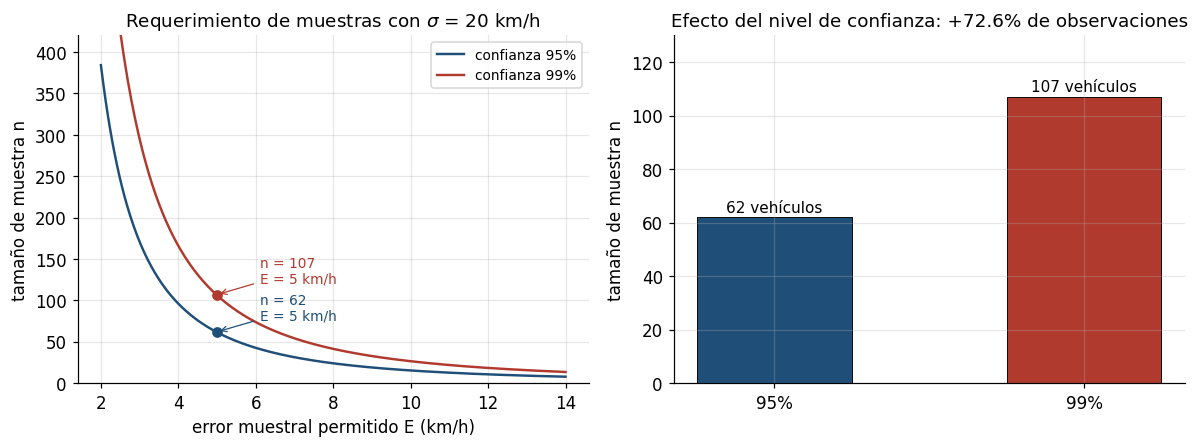

In [11]:
E_grilla = np.linspace(2, 14, 400)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

for nivel, color in [(0.95, AZUL), (0.99, ROJO)]:
    axs[0].plot(E_grilla, (Z[nivel] * sigma_v / E_grilla) ** 2, color=color, linewidth=1.6,
                label=f"confianza {nivel:.0%}")
    n_ = tamanios[nivel]
    axs[0].plot(E, n_, "o", color=color, zorder=5)
    axs[0].annotate(f"n = {n_}\nE = {E:.0f} km/h", xy=(E, n_), xytext=(E + 1.1, n_ + 14),
                    fontsize=9, color=color,
                    arrowprops=dict(arrowstyle="->", linewidth=0.8, color=color))
axs[0].set_xlabel("error muestral permitido E (km/h)")
axs[0].set_ylabel("tamaño de muestra n")
axs[0].set_ylim(0, 420)
axs[0].set_title(r"Requerimiento de muestras con $\sigma$ = 20 km/h")
axs[0].legend(fontsize=9)

barras = axs[1].bar(["95%", "99%"], [tamanios[0.95], tamanios[0.99]], width=0.5,
                    color=[AZUL, ROJO], edgecolor="black", linewidth=0.6)
for rect, nivel in zip(barras, (0.95, 0.99)):
    axs[1].text(rect.get_x() + rect.get_width() / 2, tamanios[nivel] + 2,
                f"{tamanios[nivel]} vehículos", ha="center", fontsize=10)
axs[1].set_ylabel("tamaño de muestra n")
axs[1].set_ylim(0, 130)
axs[1].set_title(f"Efecto del nivel de confianza: +{100 * (crecimiento - 1):.1f}% de observaciones")

plt.tight_layout()
plt.show()


## 5. Tensión a la rotura de un cable: tamaño de la muestra

La tensión a la rotura de un nuevo cable de acero se modela como una variable aleatoria normal con
desviación estándar $\sigma = 4$ libras. Para un nivel de confianza del 95% y un error muestral que
no supere $E = 0.5$ libras:

$$n = \left(\frac{z_{0.025}\,\sigma}{E}\right)^2 = \left(\frac{1.959964 \times 4}{0.5}\right)^2 = (15.68)^2 = 245.86 \ \Longrightarrow \ n = 246$$

El redondeo hacia arriba es obligatorio: con $n = 245$ el error sería 0.5009 libras, que excede la
tolerancia, y con $n = 246$ queda en 0.4999 libras.

El resultado se interpreta contra el ejercicio anterior. Ambos usan el mismo nivel de confianza, pero
el error relativo pedido aquí es la mitad:

$$\frac{E}{\sigma} = \frac{0.5}{4} = 0.125 \quad \text{contra} \quad \frac{5}{20} = 0.25$$

y como el tamaño crece como el inverso del cuadrado de ese cociente, reducir a la mitad el error
relativo cuadruplica el tamaño de muestra: $245.86 / 61.47 = 4$. Es la relación práctica más útil a la
hora de dimensionar un muestreo: lo que manda no es el error en unidades absolutas, sino el error
medido en desviaciones estándar.

In [12]:
sigma_cable, E_cable = 4.0, 0.5
z = Z[0.95]

n_crudo = (z * sigma_cable / E_cable) ** 2
n_cable = math.ceil(n_crudo)

print(f"sigma = {sigma_cable} libras, E = {E_cable} libras, nivel 95%: z = {z:.6f}")
print(f"n = ({z * sigma_cable:.4f}/{E_cable})^2 = {n_crudo:.4f} -> n = {n_cable}")
print()
for n_ in (n_cable - 1, n_cable):
    e_ = z * sigma_cable / math.sqrt(n_)
    print(f"   con n = {n_}: E = {z:.6f} x {sigma_cable}/{math.sqrt(n_):.4f} = {e_:.4f} "
          f"{'>' if e_ > E_cable else '<='} {E_cable}")

# contraste con el ejercicio 4: mismo nivel de confianza, distinto error relativo
n_ruta = (Z[0.95] * sigma_v / E) ** 2
print()
print(f"ejercicio 4: sigma/E = {sigma_v / E:.2f} -> n = {n_ruta:.2f}")
print(f"ejercicio 5: sigma/E = {sigma_cable / E_cable:.2f} -> n = {n_crudo:.2f}")
print(f"razon de errores relativos: {(sigma_cable / E_cable) / (sigma_v / E):.1f}, "
      f"razon de tamanios: {n_crudo / n_ruta:.1f}")


sigma = 4.0 libras, E = 0.5 libras, nivel 95%: z = 1.959964
n = (7.8399/0.5)^2 = 245.8534 -> n = 246

   con n = 245: E = 1.959964 x 4.0/15.6525 = 0.5009 > 0.5
   con n = 246: E = 1.959964 x 4.0/15.6844 = 0.4999 <= 0.5

ejercicio 4: sigma/E = 4.00 -> n = 61.46
ejercicio 5: sigma/E = 8.00 -> n = 245.85
razon de errores relativos: 2.0, razon de tamanios: 4.0


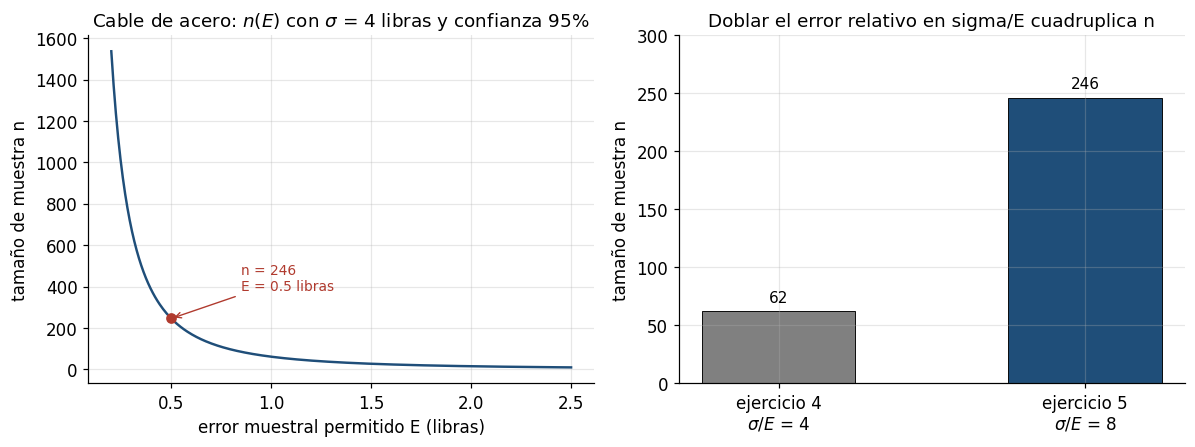

In [13]:
E_grilla = np.linspace(0.2, 2.5, 400)
n_grilla = (z * sigma_cable / E_grilla) ** 2

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

axs[0].plot(E_grilla, n_grilla, color=AZUL, linewidth=1.6)
axs[0].plot(E_cable, n_cable, "o", color=ROJO, zorder=5)
axs[0].annotate(f"n = {n_cable}\nE = 0.5 libras", xy=(E_cable, n_cable),
                xytext=(0.85, 380), fontsize=9, color=ROJO,
                arrowprops=dict(arrowstyle="->", linewidth=0.9, color=ROJO))
axs[0].set_xlabel("error muestral permitido E (libras)")
axs[0].set_ylabel("tamaño de muestra n")
axs[0].set_title(r"Cable de acero: $n(E)$ con $\sigma$ = 4 libras y confianza 95%")

barras = axs[1].bar(["ejercicio 4\n$\\sigma/E$ = 4", "ejercicio 5\n$\\sigma/E$ = 8"],
                    [math.ceil(n_ruta), n_cable], width=0.5, color=[GRIS, AZUL],
                    edgecolor="black", linewidth=0.6)
for rect, valor in zip(barras, [math.ceil(n_ruta), n_cable]):
    axs[1].text(rect.get_x() + rect.get_width() / 2, valor + 8, f"{valor}", ha="center",
                fontsize=10)
axs[1].set_ylabel("tamaño de muestra n")
axs[1].set_ylim(0, 300)
axs[1].set_title("Doblar el error relativo en sigma/E cuadruplica n")

plt.tight_layout()
plt.show()


## 6. Encuesta de satisfacción: tamaño de muestra para una proporción

Se quiere estimar la proporción de consumidores satisfechos con un producto mediante un intervalo de
confianza del 90% y con un error que no supere $E = 0.04$. A diferencia del caso de la media, la
varianza poblacional no es conocida: depende del parámetro que se ignora, de modo que el tamaño
requerido exige suponer un valor para $p$:

$$n = \frac{z_{\alpha/2}^{\,2}\, p(1-p)}{E^2}$$

### a) Sin información previa sobre $p$

Se toma $p = 0.5$, que maximiza $p(1-p) = 0.25$ y por lo tanto el tamaño requerido. Con
$z_{0.05} = 1.644854$:

$$n = \frac{(1.644854)^2 \times 0.25}{(0.04)^2} = \frac{2.70554 \times 0.25}{0.0016} = \frac{0.676385}{0.0016} = 422.74 \ \Longrightarrow \ n = 423$$

Es la elección conservadora: si la proporción real resultara distinta, el tamaño necesario solo puede
ser menor, de modo que el error especificado queda garantizado con cualquier valor de $p$.

### b) Suponiendo $p$ cerca del 30%

Con $p = 0.30$ resulta $p(1-p) = 0.21$:

$$n = \frac{2.70554 \times 0.21}{0.0016} = \frac{0.568163}{0.0016} = 355.10 \ \Longrightarrow \ n = 356$$

La información previa ahorra 67 entrevistas, un 15.8% del tamaño requerido en el peor caso. La
sensibilidad es moderada porque la parábola $p(1-p)$ es plana cerca del máximo: el peor caso ($0.25$)
está solo un 19% por encima del valor supuesto ($0.21$). Un error en la suposición de $p$ no encarece
mucho la encuesta, mientras que la elección $p = 0.5$ nunca queda corta.

In [14]:
E_prop, nivel = 0.04, 0.90
z = Z[nivel]

print(f"nivel {nivel:.0%}: z = {z:.6f}, error maximo E = {E_prop}")
print()

tamanios_p = {}
for p_supuesto, caso in [(0.5, "a) sin información previa (peor caso)"),
                         (0.4, "referencia: p = 0.4"),
                         (0.3, "b) suponiendo p = 0.3")]:
    n_crudo = z**2 * p_supuesto * (1 - p_supuesto) / E_prop**2
    n_ = math.ceil(n_crudo)
    tamanios_p[p_supuesto] = n_
    e_con_menos = z * math.sqrt(p_supuesto * (1 - p_supuesto) / (n_ - 1))
    e_con = z * math.sqrt(p_supuesto * (1 - p_supuesto) / n_)
    print(f"{caso}: p(1-p) = {p_supuesto * (1 - p_supuesto):.2f}")
    print(f"   n = ({z:.6f}^2 x {p_supuesto * (1 - p_supuesto):.2f}) / {E_prop}^2 = "
          f"{n_crudo:.4f} -> n = {n_}")
    print(f"   con n = {n_ - 1}: E = {e_con_menos:.5f} > {E_prop}   |   "
          f"con n = {n_}: E = {e_con:.5f} <= {E_prop}")
    print()

ahorro = tamanios_p[0.5] - tamanios_p[0.3]
print(f"ahorro por la información previa: {tamanios_p[0.5]} - {tamanios_p[0.3]} = {ahorro} "
      f"entrevistas ({ahorro / tamanios_p[0.5]:.1%})")
print(f"relacion de varianzas: 0.25/0.21 = {0.25 / 0.21:.4f}")


nivel 90%: z = 1.644854, error maximo E = 0.04

a) sin información previa (peor caso): p(1-p) = 0.25
   n = (1.644854^2 x 0.25) / 0.04^2 = 422.7414 -> n = 423
   con n = 422: E = 0.04004 > 0.04   |   con n = 423: E = 0.03999 <= 0.04

referencia: p = 0.4: p(1-p) = 0.24
   n = (1.644854^2 x 0.24) / 0.04^2 = 405.8317 -> n = 406
   con n = 405: E = 0.04004 > 0.04   |   con n = 406: E = 0.03999 <= 0.04

b) suponiendo p = 0.3: p(1-p) = 0.21
   n = (1.644854^2 x 0.21) / 0.04^2 = 355.1027 -> n = 356
   con n = 355: E = 0.04001 > 0.04   |   con n = 356: E = 0.03995 <= 0.04

ahorro por la información previa: 423 - 356 = 67 entrevistas (15.8%)
relacion de varianzas: 0.25/0.21 = 1.1905


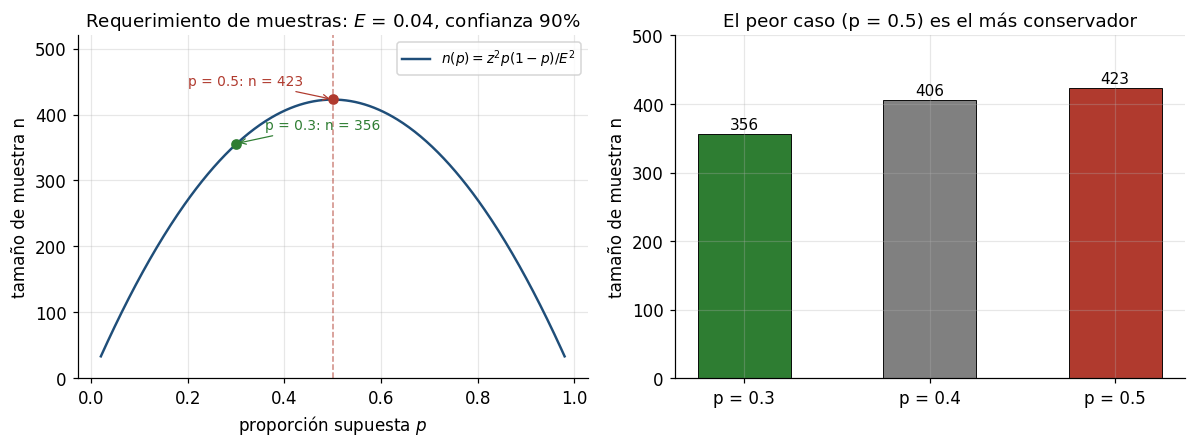

In [15]:
p_grilla = np.linspace(0.02, 0.98, 400)
n_grilla = z**2 * p_grilla * (1 - p_grilla) / E_prop**2

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))

axs[0].plot(p_grilla, n_grilla, color=AZUL, linewidth=1.6,
            label=r"$n(p) = z^2 p(1-p)/E^2$")
for p_marcado, color in [(0.3, VERDE), (0.5, ROJO)]:
    n_ = tamanios_p[p_marcado]
    axs[0].plot(p_marcado, n_, "o", color=color, zorder=5)
    axs[0].annotate(f"p = {p_marcado}: n = {n_}", xy=(p_marcado, n_),
                    xytext=(p_marcado + 0.06 if p_marcado == 0.3 else p_marcado - 0.30,
                            n_ + 22), fontsize=9, color=color,
                    arrowprops=dict(arrowstyle="->", linewidth=0.8, color=color))
axs[0].axvline(0.5, color=ROJO, linestyle="--", linewidth=1.0, alpha=0.6)
axs[0].set_xlabel(r"proporción supuesta $p$")
axs[0].set_ylabel("tamaño de muestra n")
axs[0].set_ylim(0, 520)
axs[0].set_title(r"Requerimiento de muestras: $E$ = 0.04, confianza 90%")
axs[0].legend(fontsize=9)

valores = [0.3, 0.4, 0.5]
barras = axs[1].bar([f"p = {v}" for v in valores],
                    [tamanios_p[v] for v in valores], width=0.5,
                    color=[VERDE, GRIS, ROJO], edgecolor="black", linewidth=0.6)
for rect, v in zip(barras, valores):
    axs[1].text(rect.get_x() + rect.get_width() / 2, tamanios_p[v] + 7,
                f"{tamanios_p[v]}", ha="center", fontsize=10)
axs[1].set_ylabel("tamaño de muestra n")
axs[1].set_ylim(0, 500)
axs[1].set_title("El peor caso (p = 0.5) es el más conservador")

plt.tight_layout()
plt.show()


## Notas de validación

- Los cuatro cuantiles de la tabla del marco teórico se verifican con la función error complementaria:
  las colas resultantes son 0.050000, 0.025000, 0.010000 y 0.005000, exactamente $\alpha/2$ de cada
  nivel de confianza. Todo el notebook usa esos mismos valores, de modo que las secciones son
  comparables entre sí.
- Resumen de los resultados: sección 1, $\mu \in [979.63, 988.37]$ kWh (90%) y $[977.15, 990.85]$
  (99%), con costo del 90% entre \$107,220.26 y \$108,177.34; sección 2, $p \in [0.3336, 0.4664]$
  (98%); sección 3, $p \in [0.2642, 0.5358]$ (95%), es decir entre 132 y 268 restaurantes de los 500.
  Tamaños de muestra: 62 y 107 vehículos (sección 4), 246 cables (sección 5), 423 y 356 encuestados
  (sección 6).
- En los ejercicios de tamaño de muestra se imprime el contraste de los dos enteros vecinos: el
  anterior al redondeo excede el error máximo y el redondeado lo cumple. El redondeo hacia arriba no
  es una convención, es la única opción admisible porque el error decrece con $n$.
- La cobertura Monte Carlo de la sección 1 usa 20.000 muestras de tamaño 61 de una población normal:
  la cobertura simulada coincide con el nivel declarado dentro del error de muestreo de la
  proporción, $\sqrt{(1-\alpha)\alpha/M}$, que es del orden de 0.002. La verificación confirma la
  interpretación frecuentista del nivel de confianza, no la de probabilidad posterior sobre el
  parámetro.
- Las proporciones de las secciones 2 y 3 cumplen $n\hat p \ge 5$ y $n(1-\hat p) \ge 5$, condición que
  hace razonable la aproximación normal. El intervalo de Wald construido es de cobertura aproximada;
  en la sección 3 se agrega el contraste con la corrección por finitud de la población, aplicable
  porque $n/N = 0.10$ supera el 5%.
- Los errores muestrales se recalculan siempre desde la fórmula y no se derivan de restar límites, de
  modo que la simetría del intervalo queda explícita: $\bar x - L = U - \bar x = E$.

Referencias: Walpole, R. - Probabilidad y estadística para ingeniería y ciencias. Casella, G. y
Berger, R. - Statistical Inference. Hogg, R. y Craig, J. - Introducción a la teoría de la
probabilidad y la estadística. Mood, A., Graybill, F. y Boes, D. - Introducción a la teoría de la
estadística.